In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['WenQuanYi Micro Hei', 'WenQuanYi Zen Hei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False  # 正常显示负号


# 读取数据

In [30]:
import pickle

r1 = pickle.load(open('./RES_Metric.pkl', 'rb'))
r2 = pickle.load(open('./best_agmu.pkl', 'rb'))
r3 = pickle.load(open('./GMU2.pkl', 'rb'))
r4 = pickle.load(open('./cat2.pkl', 'rb'))


In [31]:
results_1 = {
	'model_name': 'MedicalGMU',
	'fold_results': r2['fold_results'],           # {fold_idx: (labels, probs)}
}
results_2 = {
	'model_name': 'ResNet18',
	'fold_results': r1['fold_results'],
}
results_3 = {
	'model_name': 'GMU',
	'fold_results': r3['fold_results'],           # {fold_idx: (labels, probs)}
}
results_4 = {
	'model_name': 'Concate',
	'fold_results': r4['fold_results'],
}

# 绘制CURVE

## ROC Curve

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score

# 1. 扩充主色列表（至少3个颜色：蓝、粉红、绿/橙）
MODEL_COLORS = ['#E28491', '#4A90E2', '#2ECC71', '#F39C12']


def plot_roc_curves_multi(results_list, save_path='roc_multi.svg', model_colors=None):
    """
    在同一张图内绘制多个模型（如 3 个模型）的 5-Fold ROC 曲线
    """
    if model_colors is None:
        model_colors = MODEL_COLORS

    fig, ax = plt.subplots(figsize=(6.2, 5.5))
    mean_fpr = np.linspace(0, 1, 100)

    # 备用线型：除了 Ours 用实线，其余基线模型轮流用不同线型区分
    baseline_linestyles = ['--', '-.', ':']

    # 遍历每个模型（如果有 3 个模型，循环走 3 次）
    for m_idx, res in enumerate(results_list):
        model_name = res.get('model_name', f'Model {m_idx+1}')
        fold_results = res['fold_results']
        main_color = model_colors[m_idx % len(model_colors)]

        tprs = []
        fold_aucs = []

        # 1. 逐折计算 ROC 并插值
        for fold_idx, (labels, probs, *_) in fold_results.items():
            fpr, tpr, _ = roc_curve(labels, probs)
            auc = roc_auc_score(labels, probs)
            fold_aucs.append(auc)

            interp_tpr = np.interp(mean_fpr, fpr, tpr)
            interp_tpr[0] = 0.0
            tprs.append(interp_tpr)

        # 2. 计算均值与标准差
        mean_tpr = np.mean(tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = np.mean(fold_aucs)
        std_auc = np.std(fold_aucs)

        # 3. 动态配置样式（不再写死只有两个模型）
        is_ours = (model_name == 'MedicalGMU')
        if is_ours:
            linestyle = '-'
            lw = 2.4
            display_name = 'Ours'
        else:
            linestyle = baseline_linestyles[m_idx % len(baseline_linestyles)]
            lw = 1.8
            display_name = model_name

        # 绘制该模型的均值曲线
        ax.plot(
            mean_fpr, mean_tpr,
            color=main_color,
            lw=lw,
            linestyle=linestyle,
            label=f'{display_name} (AUC = {mean_auc:.3f} ± {std_auc:.3f})'
        )

        # 绘制阴影置信区间
        std_tpr = np.std(tprs, axis=0)
        tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
        tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
        ax.fill_between(mean_fpr, tprs_lower, tprs_upper, color=main_color, alpha=0.12)

    # 4. 对角线与格式美化
    ax.plot([0, 1], [0, 1], linestyle=':', color='#7F8C8D', lw=1.0)

    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('False Positive Rate', fontsize=12, fontweight='bold', labelpad=8)
    ax.set_ylabel('True Positive Rate', fontsize=12, fontweight='bold', labelpad=8)

    ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
    ax.grid(True, linestyle=':', alpha=0.35)
    ax.legend(loc='lower right', fontsize=8.8, frameon=True, edgecolor='#E0E0E0', facecolor='white')

    plt.tight_layout()
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    print(f"Saved multi-model ROC to {save_path}")

## 绘制

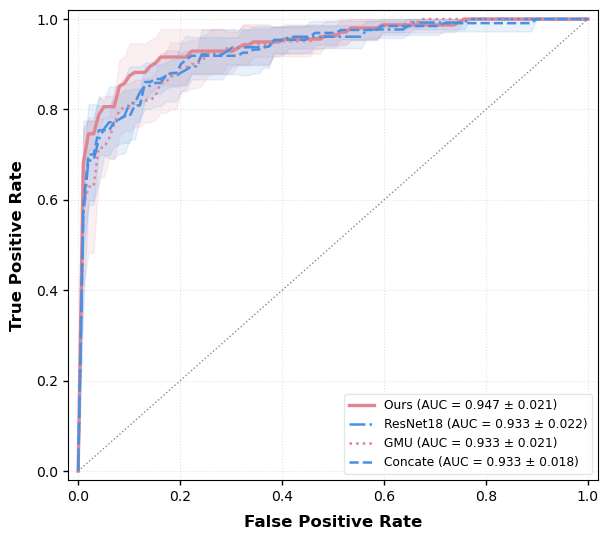

Saved multi-model ROC to roc_comparison.svg


In [32]:

# 绘制对比 ROC
plot_roc_curves_multi(
	[results_1, results_2,results_3,results_4],
	save_path='roc_comparison.svg',
	model_colors=['#E28491', '#4A90E2' ]  # 蓝=模型1, 红=模型2
)

## PR Curve

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_curve, average_precision_score

# 1. 扩充主色列表（至少准备 3~4 个期刊安全配色）
MODEL_COLORS = ['#E28491', '#4A90E2', '#2ECC71', '#F39C12']


def plot_pr_curves_multi(results_list, save_path='pr_multi.svg', model_colors=None):
    """
    在同一张图内绘制多模型（如 3 个模型）的 5-Fold PR 曲线对比（学术期刊风格）

    Args:
        results_list: list of dict, 每个 dict 包含 'model_name' 和 'fold_results'
        save_path: 图片保存路径（建议 .svg 或 .pdf）
        model_colors: 颜色列表，None 则使用默认 MODEL_COLORS
    """
    if model_colors is None:
        model_colors = MODEL_COLORS

    fig, ax = plt.subplots(figsize=(6.2, 5.5))
    mean_recall = np.linspace(0, 1, 100)

    # 备用线型：Ours 统一用实线，其他模型依次轮转不同样式的虚线
    baseline_linestyles = ['--', '-.', ':']

    all_labels = []

    # 遍历每个模型（传入 3 个模型就会循环 3 次）
    for m_idx, res in enumerate(results_list):
        model_name = res.get('model_name', f'Model {m_idx+1}')
        fold_results = res['fold_results']
        main_color = model_colors[m_idx % len(model_colors)]

        precisions = []
        fold_aps = []

        # 1. 逐折计算 PR 曲线并反向插值
        for fold_idx, (labels, probs, *_) in fold_results.items():
            all_labels.extend(labels)
            precision, recall, _ = precision_recall_curve(labels, probs)
            ap = average_precision_score(labels, probs)
            fold_aps.append(ap)

            # PR 曲线插值：recall 递增，precision 递减，需反向插值保证单调
            interp_precision = np.interp(mean_recall, recall[::-1], precision[::-1])
            interp_precision[0] = 1.0
            precisions.append(interp_precision)

        # 2. 统计该模型的均值 PR 与标准差
        mean_precision = np.mean(precisions, axis=0)
        mean_precision = np.maximum(mean_precision, 0)
        mean_ap = np.mean(fold_aps)
        std_ap = np.std(fold_aps)

        # 3. 动态配置样式与显示标签
        is_ours = (model_name == 'MedicalGMU')
        if is_ours:
            linestyle = '-'
            lw = 2.4
            display_name = 'Ours'
        else:
            # 自动为不同对比模型匹配不同的虚线样式
            linestyle = baseline_linestyles[m_idx % len(baseline_linestyles)]
            lw = 1.8
            display_name = model_name

        # 绘制均值 PR 曲线
        ax.plot(
            mean_recall, mean_precision,
            color=main_color,
            lw=lw,
            linestyle=linestyle,
            label=f'{display_name} (AP = {mean_ap:.3f} ± {std_ap:.3f})'
        )

        # 绘制标准差阴影置信区间
        std_precision = np.std(precisions, axis=0)
        precisions_upper = np.minimum(mean_precision + std_precision, 1)
        precisions_lower = np.maximum(mean_precision - std_precision, 0)
        ax.fill_between(mean_recall, precisions_lower, precisions_upper,
                        color=main_color, alpha=0.12)

    # 4. 随机分类器基线（水平线：precision = 阳性样本流行率 prevalence）
    if all_labels:
        prevalence = np.mean(all_labels)
        ax.axhline(y=prevalence, color='#7F8C8D', linestyle=':', lw=1.0,
                   label=f'Random (AP = {prevalence:.3f})')

    # 5. 坐标轴与细节美化
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.set_xlabel('Recall', fontsize=12, fontweight='bold', labelpad=8)
    ax.set_ylabel('Precision', fontsize=12, fontweight='bold', labelpad=8)

    ax.tick_params(axis='both', which='major', labelsize=10, width=1.0)
    ax.grid(True, linestyle=':', alpha=0.35)
    # PR 图通常在左下角（lower left）放图例，如果曲线遮挡可调整为 'lower right' 或 'upper right'
    ax.legend(loc='lower left', fontsize=8.8, frameon=True,
              edgecolor='#E0E0E0', facecolor='white')

    plt.tight_layout()
    plt.savefig(save_path, format='svg', bbox_inches='tight')
    plt.show()
    print(f"Saved multi-model PR curve to {save_path}")

## 绘制

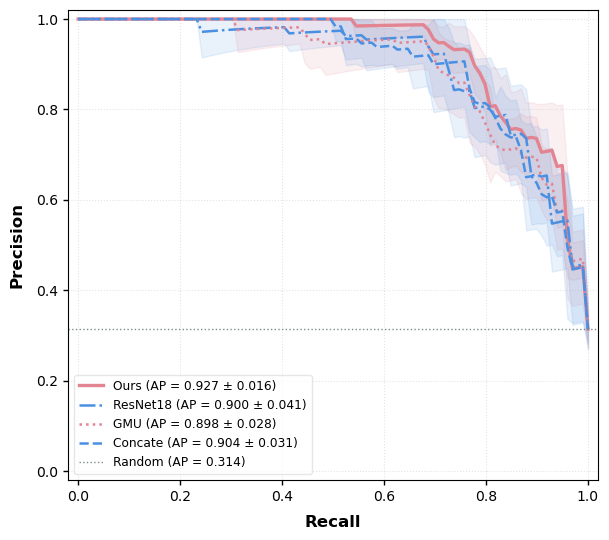

Saved multi-model PR curve to prc_comparison.svg


In [33]:
plot_pr_curves_multi([results_1, results_2,results_3,results_4],
	save_path='prc_comparison.svg',
	model_colors=['#E28491', '#4A90E2' ] )

# 显著性测试

## 数据

In [58]:
import numpy as np
import pickle
results_list = [results_1, results_2]

# ========== 正确合并方式 ==========
results_l = []
results_p = []
results_j = []

for m_idx, res in enumerate(results_list):
	
	model_name = res.get('model_name', f'Model {m_idx+1}')
	fold_results = res['fold_results']  # {fold_idx: (labels, probs)}
	print(m_idx)
	# 每个模型单独合并
	all_labels = []
	all_probs = []
	all_joint_ids = []
	for fold_idx, (fold_labels, fold_probs, fold_joint_ids) in fold_results.items():  # ← 改名！
		all_labels.extend(fold_labels)
		all_probs.extend(fold_probs)
		all_joint_ids.extend(fold_joint_ids)
	results_l.append(all_labels)
	results_p.append(all_probs)
	results_j.append(all_joint_ids)
	print(f"\n=== {model_name} ===")
	print(f"总样本数: {len(all_labels)}")
	print(f"正例数: {sum(all_labels)}")
	print(f"负例数: {len(all_labels) - sum(all_labels)}")
	print(f"合并AUC: {roc_auc_score(all_labels, all_probs):.4f}")
	

0

=== MedicalGMU ===
总样本数: 430
正例数: 135
负例数: 295
合并AUC: 0.9389
1

=== ResNet18 ===
总样本数: 430
正例数: 135
负例数: 295
合并AUC: 0.9312


## ROC差异

In [ ]:
import numpy as np
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from scipy import stats
from scipy.stats import norm
import warnings

# ============================================================
# 1. DeLong 检验（AUC差异显著性）—— 最核心
# ============================================================

def compute_midrank(x):
	"""计算中位秩"""
	J = np.argsort(x)
	Z = x[J]
	N = len(x)
	T = np.zeros(N, dtype=float)
	i = 0
	while i < N:
		j = i
		while j < N and Z[j] == Z[i]:
			j += 1
		T[i:j] = 0.5 * (i + j - 1)
		i = j
	T2 = np.empty(N, dtype=float)
	T2[J] = T + 1
	return T2

def fastDeLong(predictions_sorted_transposed, label_1_count):
	"""快速DeLong检验"""
	m = label_1_count
	n = predictions_sorted_transposed.shape[1] - m
	positive_examples = predictions_sorted_transposed[:, :m]
	negative_examples = predictions_sorted_transposed[:, m:]
	k = predictions_sorted_transposed.shape[0]
	
	tx = np.empty([k, m], dtype=float)
	ty = np.empty([k, n], dtype=float)
	tz = np.empty([k, m + n], dtype=float)
	
	for r in range(k):
		tx[r, :] = compute_midrank(positive_examples[r, :])
		ty[r, :] = compute_midrank(negative_examples[r, :])
		tz[r, :] = compute_midrank(predictions_sorted_transposed[r, :])
	
	aucs = tz[:, :m].sum(axis=1) / m / n - float(m + 1.0) / 2.0 / n
	v01 = (tz[:, :m] - tx[:, :]) / n
	v10 = 1.0 - (tz[:, m:] - ty[:, :]) / m
	
	sx = np.cov(v01)
	sy = np.cov(v10)
	delongcov = sx / m + sy / n
	
	return aucs, delongcov

def calc_pvalue(aucs, sigma):
	"""计算DeLong检验p值"""
	l = np.array([[1, -1]])
	z = np.abs(np.diff(aucs)) / np.sqrt(np.dot(np.dot(l, sigma), l.T))
	p_value = 2 * (1 - norm.cdf(z[0][0]))
	return p_value, z[0][0]

def compute_ground_truth_statistics(ground_truth):
	"""计算真实标签统计"""
	assert np.array_equal(np.unique(ground_truth), [0, 1])
	order = (-ground_truth).argsort()
	label_1_count = int(ground_truth.sum())
	return order, label_1_count

def delong_test(y_true, prob1, prob2):
	"""
	DeLong检验：比较两个模型的AUC是否有显著差异
	
	Parameters:
		y_true: 真实标签 (n_samples,)
		prob1: 模型1预测概率 (n_samples,)
		prob2: 模型2预测概率 (n_samples,)
	
	Returns:
		auc1, auc2, p_value, z_score, auc_diff, ci_lower, ci_upper
	"""
	y_true = np.array(y_true)
	prob1 = np.array(prob1)
	prob2 = np.array(prob2)
	
	# 单独计算AUC
	auc1 = roc_auc_score(y_true, prob1)
	auc2 = roc_auc_score(y_true, prob2)
	
	# DeLong检验
	predictions = np.vstack([prob1, prob2])
	order, label_1_count = compute_ground_truth_statistics(y_true)
	predictions_sorted = predictions[:, order]
	
	aucs, delongcov = fastDeLong(predictions_sorted, label_1_count)
	p_value, z_score = calc_pvalue(aucs, delongcov)
	
	# AUC差异的95% CI (简化版)
	auc_diff = auc2 - auc1
	se_diff = np.sqrt(np.dot(np.dot(np.array([[1, -1]]), delongcov), np.array([[1, -1]]).T))[0][0]
	ci_lower = auc_diff - 1.96 * se_diff
	ci_upper = auc_diff + 1.96 * se_diff
	
	return {
		'auc1': auc1,
		'auc2': auc2,
		'auc_diff': auc_diff,
		'z_score': z_score,
		'p_value': p_value,
		'ci_95': (ci_lower, ci_upper),
		'se_diff': se_diff
	}


# ============================================================
# 2. McNemar 检验（敏感性/特异性差异）
# ============================================================

def mcnemar_test(y_true, pred1, pred2):
	"""
	McNemar检验：比较两个分类器在配对样本上的差异
	
	用于比较：敏感性、特异性、准确率等在特定阈值下的差异
	
	Parameters:
		y_true: 真实标签
		pred1: 模型1预测结果 (0/1)
		pred2: 模型2预测结果 (0/1)
	
	Returns:
		dict with statistic, p_value, and contingency table
	"""
	y_true = np.array(y_true)
	pred1 = np.array(pred1)
	pred2 = np.array(pred2)
	
	# 构建2x2列联表
	# b: 模型1错，模型2对
	# c: 模型1对，模型2错
	n_11 = np.sum((pred1 == y_true) & (pred2 == y_true))  # 都对
	n_10 = np.sum((pred1 == y_true) & (pred2 != y_true))  # 模型1对，模型2错
	n_01 = np.sum((pred1 != y_true) & (pred2 == y_true))  # 模型1错，模型2对
	n_00 = np.sum((pred1 != y_true) & (pred2 != y_true))  # 都错
	
	# McNemar检验统计量 (连续性校正)
	if n_10 + n_01 > 0:
		statistic = (abs(n_01 - n_10) - 1) ** 2 / (n_01 + n_10)
		p_value = 1 - stats.chi2.cdf(statistic, 1)
	else:
		statistic = 0
		p_value = 1.0
	
	return {
		'statistic': statistic,
		'p_value': p_value,
		'n_both_correct': n_11,
		'n_model1_wrong_model2_right': n_01,
		'n_model1_right_model2_wrong': n_10,
		'n_both_wrong': n_00,
		'table': np.array([[n_11, n_10], [n_01, n_00]])
	}


def compare_sensitivity_specificity(y_true, prob1, prob2, threshold=0.5):
	"""
	比较两个模型在特定阈值下的敏感性和特异性
	
	Returns:
		包含敏感性、特异性、McNemar检验结果的字典
	"""
	pred1 = (np.array(prob1) >= threshold).astype(int)
	pred2 = (np.array(prob2) >= threshold).astype(int)
	y_true = np.array(y_true)
	
	# 计算混淆矩阵
	cm1 = confusion_matrix(y_true, pred1)
	cm2 = confusion_matrix(y_true, pred2)
	
	# 敏感性 (Recall)
	sen1 = cm1[1, 1] / (cm1[1, 1] + cm1[1, 0]) if (cm1[1, 1] + cm1[1, 0]) > 0 else 0
	sen2 = cm2[1, 1] / (cm2[1, 1] + cm2[1, 0]) if (cm2[1, 1] + cm2[1, 0]) > 0 else 0
	
	# 特异性
	spe1 = cm1[0, 0] / (cm1[0, 0] + cm1[0, 1]) if (cm1[0, 0] + cm1[0, 1]) > 0 else 0
	spe2 = cm2[0, 0] / (cm2[0, 0] + cm2[0, 1]) if (cm2[0, 0] + cm2[0, 1]) > 0 else 0
	
	# 准确率
	acc1 = (cm1[0, 0] + cm1[1, 1]) / cm1.sum()
	acc2 = (cm2[0, 0] + cm2[1, 1]) / cm2.sum()
	
	# 分别对阳性和阴性做McNemar检验
	# 阳性样本：比较敏感性
	pos_mask = y_true == 1
	mcnemar_sen = mcnemar_test(y_true[pos_mask], pred1[pos_mask], pred2[pos_mask])
	
	# 阴性样本：比较特异性
	neg_mask = y_true == 0
	mcnemar_spe = mcnemar_test(y_true[neg_mask], pred1[neg_mask], pred2[neg_mask])
	
	# 总体准确率
	mcnemar_acc = mcnemar_test(y_true, pred1, pred2)
	
	return {
		'sensitivity': {'model1': sen1, 'model2': sen2, 'diff': sen2 - sen1},
		'specificity': {'model1': spe1, 'model2': spe2, 'diff': spe2 - spe1},
		'accuracy': {'model1': acc1, 'model2': acc2, 'diff': acc2 - acc1},
		'mcnemar_sensitivity': mcnemar_sen,
		'mcnemar_specificity': mcnemar_spe,
		'mcnemar_accuracy': mcnemar_acc,
		'confusion_matrix_1': cm1,
		'confusion_matrix_2': cm2
	}


# ============================================================
# 3. NRI / IDI 计算
# ============================================================

def calculate_nri(y_true, prob_old, prob_new, threshold=0.5):
	"""
	计算Net Reclassification Improvement (NRI)
	
	NRI = P(Up|Event) - P(Down|Event) + P(Down|Non-event) - P(Up|Non-event)
	
	Parameters:
		y_true: 真实标签
		prob_old: 旧模型概率
		prob_new: 新模型概率
		threshold: 分类阈值
	
	Returns:
		NRI及组件
	"""
	y_true = np.array(y_true)
	prob_old = np.array(prob_old)
	prob_new = np.array(prob_new)
	
	# 预测类别
	pred_old = (prob_old >= threshold).astype(int)
	pred_new = (prob_new >= threshold).astype(int)
	
	# 事件组和非事件组
	events = y_true == 1
	nonevents = y_true == 0
	
	n_events = np.sum(events)
	n_nonevents = np.sum(nonevents)
	
	if n_events == 0 or n_nonevents == 0:
		raise ValueError("需要同时包含阳性和阴性样本")
	
	# 事件组重分类
	n_up_events = np.sum((pred_new == 1) & (pred_old == 0) & events)
	n_down_events = np.sum((pred_new == 0) & (pred_old == 1) & events)
	
	# 非事件组重分类
	n_up_nonevents = np.sum((pred_new == 1) & (pred_old == 0) & nonevents)
	n_down_nonevents = np.sum((pred_new == 0) & (pred_old == 1) & nonevents)
	
	# 计算概率
	p_up_events = n_up_events / n_events
	p_down_events = n_down_events / n_events
	p_up_nonevents = n_up_nonevents / n_nonevents
	p_down_nonevents = n_down_nonevents / n_nonevents
	
	# NRI组件
	nri_events = p_up_events - p_down_events
	nri_nonevents = p_down_nonevents - p_up_nonevents
	nri = nri_events + nri_nonevents
	
	# 标准误和95% CI
	var_nri = (p_up_events + p_down_events) / n_events + \
				(p_up_nonevents + p_down_nonevents) / n_nonevents
	se_nri = np.sqrt(var_nri)
	z_nri = nri / se_nri if se_nri > 0 else 0
	p_nri = 2 * (1 - norm.cdf(abs(z_nri)))
	
	return {
		'NRI': nri,
		'NRI_events': nri_events,
		'NRI_nonevents': nri_nonevents,
		'p_value': p_nri,
		'z_score': z_nri,
		'se': se_nri,
		'ci_95': (nri - 1.96 * se_nri, nri + 1.96 * se_nri),
		'details': {
			'n_up_events': n_up_events,
			'n_down_events': n_down_events,
			'n_up_nonevents': n_up_nonevents,
			'n_down_nonevents': n_down_nonevents,
			'n_events': n_events,
			'n_nonevents': n_nonevents
		}
	}


def calculate_idi(y_true, prob_old, prob_new):
	"""
	计算Integrated Discrimination Improvement (IDI)
	
	IDI = [P(New|Event) - P(Old|Event)] - [P(New|Non-event) - P(Old|Non-event)]
		= 事件组平均概率提升 - 非事件组平均概率提升
	
	Parameters:
		y_true: 真实标签
		prob_old: 旧模型概率
		prob_new: 新模型概率
	
	Returns:
		IDI及组件
	"""
	y_true = np.array(y_true)
	prob_old = np.array(prob_old)
	prob_new = np.array(prob_new)
	
	events = y_true == 1
	nonevents = y_true == 0
	
	# 事件组平均预测概率
	mean_prob_old_events = np.mean(prob_old[events])
	mean_prob_new_events = np.mean(prob_new[events])
	
	# 非事件组平均预测概率
	mean_prob_old_nonevents = np.mean(prob_old[nonevents])
	mean_prob_new_nonevents = np.mean(prob_new[nonevents])
	
	# IDI组件
	idi_events = mean_prob_new_events - mean_prob_old_events
	idi_nonevents = mean_prob_new_nonevents - mean_prob_old_nonevents
	idi = idi_events - idi_nonevents
	
	# 标准误（Bootstrap方法更精确，这里用近似公式）
	n_events = np.sum(events)
	n_nonevents = np.sum(nonevents)
	
	var_events = np.var(prob_new[events] - prob_old[events], ddof=1) / n_events
	var_nonevents = np.var(prob_new[nonevents] - prob_old[nonevents], ddof=1) / n_nonevents
	
	se_idi = np.sqrt(var_events + var_nonevents)
	z_idi = idi / se_idi if se_idi > 0 else 0
	p_idi = 2 * (1 - norm.cdf(abs(z_idi)))
	
	return {
		'IDI': idi,
		'IDI_events': idi_events,
		'IDI_nonevents': idi_nonevents,
		'p_value': p_idi,
		'z_score': z_idi,
		'se': se_idi,
		'ci_95': (idi - 1.96 * se_idi, idi + 1.96 * se_idi),
		'mean_probs': {
			'old_events': mean_prob_old_events,
			'new_events': mean_prob_new_events,
			'old_nonevents': mean_prob_old_nonevents,
			'new_nonevents': mean_prob_new_nonevents
		}
	}


# ============================================================
# 4. 综合函数：一次性计算所有三个指标
# ============================================================

def comprehensive_comparison(y_true, prob_baseline, prob_ours, 
								threshold=0.5,
								model_names=('Baseline', 'Ours')):
	"""
	综合比较两个模型：DeLong + McNemar + NRI/IDI
	
	Parameters:
		y_true: 真实标签
		prob_baseline: 基线模型预测概率
		prob_ours: 你的模型预测概率
		threshold: 分类阈值
		model_names: 模型名称
	
	Returns:
		包含所有检验结果的字典
	"""
	print("=" * 70)
	print("COMPREHENSIVE STATISTICAL COMPARISON")
	print("=" * 70)
	
	# ---------- 4.1 DeLong检验 ----------
	print(f"\n{'='*60}")
	print("1. DeLong Test (AUC Comparison)")
	print(f"{'='*60}")
	
	delong = delong_test(y_true, prob_baseline, prob_ours)
	print(f"{model_names[0]} AUC: {delong['auc1']:.4f}")
	print(f"{model_names[1]} AUC: {delong['auc2']:.4f}")
	print(f"AUC Difference: {delong['auc_diff']:.4f}")
	print(f"95% CI: [{delong['ci_95'][0]:.4f}, {delong['ci_95'][1]:.4f}]")
	print(f"Z-score: {delong['z_score']:.4f}")
	print(f"p-value: {delong['p_value']:.2e}")
	print(f"Significant: {'Yes' if delong['p_value'] < 0.05 else 'No'}")
	
	# ---------- 4.2 McNemar检验 ----------
	print(f"\n{'='*60}")
	print("2. McNemar Test (Sensitivity/Specificity at threshold={})".format(threshold))
	print(f"{'='*60}")
	
	mcnemar = compare_sensitivity_specificity(y_true, prob_baseline, prob_ours, threshold)
	
	print(f"Sensitivity: {model_names[0]}={mcnemar['sensitivity']['model1']:.4f}, "
			f"{model_names[1]}={mcnemar['sensitivity']['model2']:.4f}")
	print(f"  Difference p-value: {mcnemar['mcnemar_sensitivity']['p_value']:.4f}")
	
	print(f"Specificity: {model_names[0]}={mcnemar['specificity']['model1']:.4f}, "
			f"{model_names[1]}={mcnemar['specificity']['model2']:.4f}")
	print(f"  Difference p-value: {mcnemar['mcnemar_specificity']['p_value']:.4f}")
	
	print(f"Accuracy: {model_names[0]}={mcnemar['accuracy']['model1']:.4f}, "
			f"{model_names[1]}={mcnemar['accuracy']['model2']:.4f}")
	print(f"  Difference p-value: {mcnemar['mcnemar_accuracy']['p_value']:.4f}")
	
	# ---------- 4.3 NRI/IDI ----------
	print(f"\n{'='*60}")
	print("3. NRI / IDI (Reclassification Improvement)")
	print(f"{'='*60}")
	
	nri = calculate_nri(y_true, prob_baseline, prob_ours, threshold)
	print(f"NRI: {nri['NRI']:.4f} (95% CI: {nri['ci_95'][0]:.4f}, {nri['ci_95'][1]:.4f})")
	print(f"  Events NRI: {nri['NRI_events']:.4f}")
	print(f"  Non-events NRI: {nri['NRI_nonevents']:.4f}")
	print(f"  p-value: {nri['p_value']:.4f}")
	
	idi = calculate_idi(y_true, prob_baseline, prob_ours)
	print(f"\nIDI: {idi['IDI']:.4f} (95% CI: {idi['ci_95'][0]:.4f}, {idi['ci_95'][1]:.4f})")
	print(f"  Events IDI: {idi['IDI_events']:.4f}")
	print(f"  Non-events IDI: {idi['IDI_nonevents']:.4f}")
	print(f"  p-value: {idi['p_value']:.4f}")
	
	# 综合结果
	results = {
		'delong': delong,
		'mcnemar': mcnemar,
		'nri': nri,
		'idi': idi
	}
	
	print(f"\n{'='*70}")
	print("SUMMARY")
	print(f"{'='*70}")
	print(f"AUC improvement: {delong['auc_diff']:.4f} (p={delong['p_value']:.2e})")
	print(f"NRI: {nri['NRI']:.4f} (p={nri['p_value']:.4f})")
	print(f"IDI: {idi['IDI']:.4f} (p={idi['p_value']:.4f})")
	
	return results



 ## Sensitivity 和 Specificity 差异

In [27]:
import numpy as np
from sklearn.metrics import confusion_matrix
from scipy.stats import chi2
from collections import defaultdict


def mcnemar_test_sensitivity_specificity(y_true, pred1, pred2):
	"""
	McNemar 检验：比较两个模型的 Sensitivity 和 Specificity 差异
	
	适用于配对设计（同一组样本，两个模型预测）
	
	Parameters:
		y_true: 真实标签 (n_samples,)
		pred1: 模型1预测结果 (0/1)
		pred2: 模型2预测结果 (0/1)
	
	Returns:
		dict: sensitivity差异的p值, specificity差异的p值, 混淆矩阵等
	"""
	pred1 = (pred1 > 0.25).astype(int)
	pred2 = (pred2 > 0.25).astype(int)

	y_true = np.array(y_true)
	pred1 = np.array(pred1)
	pred2 = np.array(pred2)
	
	# ========== 1. 总体准确率比较（标准McNemar）==========
	# 构建 2x2 表
	#          模型2正确    模型2错误
	# 模型1正确   n11         n10
	# 模型1错误   n01         n00
	
	n11 = np.sum((pred1 == y_true) & (pred2 == y_true))   # 都对
	n10 = np.sum((pred1 == y_true) & (pred2 != y_true))    # 模型1对，模型2错
	n01 = np.sum((pred1 != y_true) & (pred2 == y_true))    # 模型1错，模型2对
	n00 = np.sum((pred1 != y_true) & (pred2 != y_true))    # 都错
	
	# McNemar 统计量（连续性校正）
	if n10 + n01 > 0:
		mcnemar_stat = (abs(n10 - n01) - 1) ** 2 / (n10 + n01)
		p_accuracy = 1 - chi2.cdf(mcnemar_stat, 1)
	else:
		mcnemar_stat = 0
		p_accuracy = 1.0
	
	# ========== 2. Sensitivity 比较（仅在阳性样本中）==========
	pos_mask = y_true == 1
	
	if np.sum(pos_mask) > 0:
		pred1_pos = pred1[pos_mask]
		pred2_pos = pred2[pos_mask]
		y_true_pos = y_true[pos_mask]
		
		# 阳性中的混淆
		tp1 = np.sum((pred1_pos == 1) & (y_true_pos == 1))
		fn1 = np.sum((pred1_pos == 0) & (y_true_pos == 1))
		tp2 = np.sum((pred2_pos == 1) & (y_true_pos == 1))
		fn2 = np.sum((pred2_pos == 0) & (y_true_pos == 1))
		
		sens1 = tp1 / (tp1 + fn1) if (tp1 + fn1) > 0 else 0
		sens2 = tp2 / (tp2 + fn2) if (tp2 + fn2) > 0 else 0
		
		# McNemar for sensitivity: 比较两个模型在阳性样本中的预测
		# 表: 模型2预测1  模型2预测0
		# 模型1预测1   a          b
		# 模型1预测0   c          d
		a = np.sum((pred1_pos == 1) & (pred2_pos == 1))  # 都预测正确(TP)
		b = np.sum((pred1_pos == 1) & (pred2_pos == 0))  # 模型1对，模型2错(FN)
		c = np.sum((pred1_pos == 0) & (pred2_pos == 1))  # 模型1错，模型2对(TP)
		d = np.sum((pred1_pos == 0) & (pred2_pos == 0))  # 都错(FN)
		
		if b + c > 0:
			mcnemar_sens = (abs(b - c) - 1) ** 2 / (b + c)
			p_sensitivity = 1 - chi2.cdf(mcnemar_sens, 1)
		else:
			p_sensitivity = 1.0
	else:
		sens1 = sens2 = 0
		p_sensitivity = 1.0
		a = b = c = d = 0
	
	# ========== 3. Specificity 比较（仅在阴性样本中）==========
	neg_mask = y_true == 0
	
	if np.sum(neg_mask) > 0:
		pred1_neg = pred1[neg_mask]
		pred2_neg = pred2[neg_mask]
		y_true_neg = y_true[neg_mask]
		
		tn1 = np.sum((pred1_neg == 0) & (y_true_neg == 0))
		fp1 = np.sum((pred1_neg == 1) & (y_true_neg == 0))
		tn2 = np.sum((pred2_neg == 0) & (y_true_neg == 0))
		fp2 = np.sum((pred2_neg == 1) & (y_true_neg == 0))
		
		spec1 = tn1 / (tn1 + fp1) if (tn1 + fp1) > 0 else 0
		spec2 = tn2 / (tn2 + fp2) if (tn2 + fp2) > 0 else 0
		
		# McNemar for specificity
		a_sp = np.sum((pred1_neg == 0) & (pred2_neg == 0))  # 都正确(TN)
		b_sp = np.sum((pred1_neg == 0) & (pred2_neg == 1))  # 模型1对，模型2错(FP)
		c_sp = np.sum((pred1_neg == 1) & (pred2_neg == 0))  # 模型1错，模型2对(TN)
		d_sp = np.sum((pred1_neg == 1) & (pred2_neg == 1))  # 都错(FP)
		
		if b_sp + c_sp > 0:
			mcnemar_spec = (abs(b_sp - c_sp) - 1) ** 2 / (b_sp + c_sp)
			p_specificity = 1 - chi2.cdf(mcnemar_spec, 1)
		else:
			p_specificity = 1.0
	else:
		spec1 = spec2 = 0
		p_specificity = 1.0
		a_sp = b_sp = c_sp = d_sp = 0
	
	return {
		'sensitivity': {
			'model1': float(sens1),
			'model2': float(sens2),
			'diff': float(sens2 - sens1),
			'p_value': float(p_sensitivity),
			'table': {'a': int(a), 'b': int(b), 'c': int(c), 'd': int(d)}
		},
		'specificity': {
			'model1': float(spec1),
			'model2': float(spec2),
			'diff': float(spec2 - spec1),
			'p_value': float(p_specificity),
			'table': {'a': int(a_sp), 'b': int(b_sp), 'c': int(c_sp), 'd': int(d_sp)}
		},
		'accuracy': {
			'p_value': float(p_accuracy),
			'table': {'n11': int(n11), 'n10': int(n10), 'n01': int(n01), 'n00': int(n00)}
		}
	}



## AP 差异

In [28]:
from sklearn.metrics import average_precision_score
import numpy as np

def ap_permutation_test(y_true, prob1, prob2, n_perm=10000, seed=42):
    y_true = np.array(y_true)
    prob1, prob2 = np.array(prob1), np.array(prob2)
    
    ap1 = average_precision_score(y_true, prob1)
    ap2 = average_precision_score(y_true, prob2)
    obs_diff = ap2 - ap1
    
    rng = np.random.RandomState(seed)
    perm_diffs = np.zeros(n_perm)
    
    for i in range(n_perm):
        swap = rng.rand(len(y_true)) < 0.5
        p1 = np.where(swap, prob2, prob1)
        p2 = np.where(swap, prob1, prob2)
        perm_diffs[i] = average_precision_score(y_true, p2) - average_precision_score(y_true, p1)
    
    p = np.mean(np.abs(perm_diffs) >= np.abs(obs_diff))
    return {'ap1': ap1, 'ap2': ap2, 'diff': obs_diff, 'p': p}

# 使用：在图像层面 (n=1,247) 做
# result = ap_permutation_test(y_true, prob_base, prob_gmu, n_perm=10000)

## 运行

In [59]:
import numpy as np
from sklearn.metrics import roc_auc_score

# ========== 1. 转置为 n x 2 方便处理 ==========

labels = np.array(results_l).T      # n x 2
probs = np.array(results_p).T        # n x 2
joint_ids = np.array(results_j).T  # n x 2

# 现在：
# labels[i] = [label_base_i, label_ours_i]
# probs[i] = [prob_base_i, prob_ours_i]
# joint_ids[i] = [jid_base_i, jid_ours_i]

print(f"形状: labels={labels.shape}, probs={probs.shape}, joint_ids={joint_ids.shape}")

# ========== 2. 检查并处理 ==========

# 情况A：两列joint_id完全相同（只是可能顺序不同）
if np.array_equal(joint_ids[:, 0], joint_ids[:, 1]):
	print("两列joint_id相同，直接提取")
	labels_base = labels[:, 0]
	labels_ours = labels[:, 1]
	probs_base = probs[:, 0]
	probs_ours = probs[:, 1]
	
	# 检查标签一致
	assert np.array_equal(labels_base, labels_ours), "标签不一致！"
	
# 情况B：两列joint_id不同，需要按joint_id对齐
else:
	print("两列joint_id不同，需要按joint_id对齐")
	
	# 建立字典: {joint_id: (label, prob)}
	base_dict = {}
	for i in range(len(joint_ids)):
		jid = joint_ids[i, 1]
		base_dict[jid] = (labels[i, 1], probs[i, 1])
	
	ours_dict = {}
	for i in range(len(joint_ids)):
		jid = joint_ids[i, 0]
		ours_dict[jid] = (labels[i, 0], probs[i, 0])
	
	# 取交集
	common_jids = sorted(set(base_dict.keys()) & set(ours_dict.keys()))
	print(f"基线模型joint数: {len(base_dict)}")
	print(f"改进模型joint数: {len(ours_dict)}")
	print(f"共同joint数: {len(common_jids)}")
	
	labels_base, probs_base = [], []
	labels_ours, probs_ours = [], []
	
	for jid in common_jids:
		l_b, p_b = base_dict[jid]
		l_o, p_o = ours_dict[jid]
		
		assert l_b == l_o, f"joint {jid} 标签不一致: {l_b} vs {l_o}"
		
		labels_base.append(l_b)
		probs_base.append(p_b)
		labels_ours.append(l_o)
		probs_ours.append(p_o)
	
	labels_base = np.array(labels_base)
	labels_ours = np.array(labels_ours)
	probs_base = np.array(probs_base)
	probs_ours = np.array(probs_ours)

 

print(f"\n基线模型样本数: {len(labels_base)}")
print(f"改进模型样本数: {len(labels_ours)}")

result = delong_test(labels_ours, probs_base, probs_ours)
mcnemar_result = mcnemar_test_sensitivity_specificity(labels_ours, probs_base, probs_ours)

print(f"\n{'='*60}")
print("DeLong 检验结果")
print(f"{'='*60}")
print(f"基线 AUC: {result['auc1']:.4f}")
print(f"改进 AUC: {result['auc2']:.4f}")
print(f"AUC差异: {result['auc_diff']:.4f}")
print(f"95% CI: [{result['ci_95'][0]:.4f}, {result['ci_95'][1]:.4f}]")
print(f"Z-score: {result['z_score']:.4f}")
print(f"p-value: {result['p_value']:.2e}")



# ========== 输出 ==========
print(f"{'='*60}")
print("Sensitivity & Specificity Comparison (McNemar Test)")
print(f"{'='*60}")
sen_result = mcnemar_result['sensitivity']
spe_result = mcnemar_result['specificity']
print(f"\n--- Sensitivity (Positive Samples) ---")
print(f"基线模型:  {sen_result['model1']:.4f}")
print(f"改进模型: {sen_result['model2']:.4f}")
print(f"Difference: {sen_result['diff']:.4f}")
print(f" p-value = {sen_result['p_value']:.4f}")

print(f"\n--- Specificity (Negative Samples) ---")
print(f"基线模型:  {spe_result['model1']:.4f}")
print(f"改进模型: {spe_result['model2']:.4f}")
print(f"Difference: {spe_result['diff']:.4f}")
print(f" p-value = {spe_result['p_value']:.4f}")

aaa = ap_permutation_test(labels_base, probs_base, probs_ours, n_perm=10000)
print(aaa)

形状: labels=(430, 2), probs=(430, 2), joint_ids=(430, 2)
两列joint_id不同，需要按joint_id对齐
基线模型joint数: 430
改进模型joint数: 430
共同joint数: 430

基线模型样本数: 430
改进模型样本数: 430

DeLong 检验结果
基线 AUC: 0.9312
改进 AUC: 0.9389
AUC差异: 0.0077
95% CI: [-0.0110, 0.0265]
Z-score: 0.8056
p-value: 4.20e-01
Sensitivity & Specificity Comparison (McNemar Test)

--- Sensitivity (Positive Samples) ---
基线模型:  0.8889
改进模型: 0.9185
Difference: 0.0296
 p-value = 0.3865

--- Specificity (Negative Samples) ---
基线模型:  0.7966
改进模型: 0.8136
Difference: 0.0169
 p-value = 0.5108
{'ap1': 0.8983787631399706, 'ap2': 0.9047778287846392, 'diff': 0.006399065644668633, 'p': np.float64(0.6046)}
